# Homework 5 — City dropdown and an accessible palette

**Task.** Add a dropdown menu for the cities in the data. Use another colour for
the SPLOM base chart so it is easy to tell apart from the weather categorical
encoding. Check accessibility with Coblis and adjust colours accordingly.
Export a single HTML file.

The dashboard combines all four composition operators — `repeat` for the scatter
plot matrix, `layer` + `repeat` for the monthly averages, `facet` for the
temperature histograms, and `concat` to assemble them.

In [1]:
"""Homework 5 - weather dashboard with a city dropdown and an accessible palette."""
import numpy as np, itertools, altair as alt
from hw4 import simulate, rgb_to_lab, MACHADO

# NB: vega_datasets' `weather` attribute points at a different dataset entirely
# (a forecast table with day/record/normal columns and no `location` field).
# The Seattle / New York series this dashboard needs lives in weather.csv.
weather = 'https://vega.github.io/vega-datasets/data/weather.csv'

## A trap in the data source

`vega_datasets`' `weather` attribute points at a *different dataset* — a
forecast table with `day` / `record` / `normal` columns and no `location` field
at all. Filtering it by city silently yields an empty dashboard rather than an
error. The Seattle and New York series this assignment needs live in
`weather.csv`.

## Choosing the categorical palette

The original palette has a real problem, and it is not visible to normal
vision. Measured in CIELAB after applying the Machado et al. (2009) dichromacy
matrices, its worst pair is **rain versus snow at ΔE 5.7 under protanopia** —
effectively the same colour.

Rather than guess a replacement, the search below fixes a small set of
semantically acceptable hues per category — drizzle must read as a light blue,
rain as a darker blue, fog as grey, snow as near-white, sun as warm — and then
picks the assignment that maximises the *worst* pairwise separation across
normal vision and all three dichromacies.

Constraining first matters. Optimising without constraints gives a palette with
ΔE 31.0 that assigns **black to sun and yellow to drizzle**: perceptually ideal,
semantically absurd.

In [2]:
# --- palette chosen by constrained optimisation (see README) -----------------
WEATHER_CATS   = ['drizzle', 'fog', 'rain', 'snow', 'sun']
WEATHER_COLORS = ['#56B4E9', '#999999', '#08519C', '#EDEDED', '#E69F00']

def hex2rgb(h):
    h = h.lstrip('#'); return np.array([int(h[i:i+2], 16) for i in (0, 2, 4)])

def min_delta_e(candidate, palette=WEATHER_COLORS):
    """Smallest perceived distance from `candidate` to any palette colour,
    across normal vision and all three dichromacies."""
    cols = np.array([hex2rgb(candidate)] + [hex2rgb(c) for c in palette])
    worst = 1e9
    for v in ['Normal'] + list(MACHADO):
        sim = cols if v == 'Normal' else simulate(cols, v)
        lab = rgb_to_lab(sim)
        worst = min(worst, min(np.linalg.norm(lab[0] - lab[k])
                               for k in range(1, len(cols))))
    return worst

# The SPLOM encodes no category, so its colour must not be mistakable for one.
# Altair's default (#4c78a8) sits right next to the blues used for rain/drizzle.
SPLOM_CANDIDATES = {'altair default': '#4c78a8', 'bluish green': '#009E73',
                    'reddish purple': '#CC79A7', 'charcoal': '#333333',
                    'vermillion': '#D55E00'}

# furthest from every weather colour under all vision types (audited below)
SPLOM_COLOR = '#333333'

## Choosing the SPLOM colour

The SPLOM encodes no category, so its colour must not look like one. Altair's
default (`#4c78a8`) sits right next to the blues used for rain and drizzle,
which is exactly the confusion the assignment asks to avoid.

The audit below measures each candidate's distance to the *nearest* weather
colour, under every vision type. Worth noting that my first instinct —
Okabe-Ito's bluish green — scored **worse than the default** (11.9 vs 13.4).
Charcoal wins at 29.4, and it also reads as "neutral, not a category".

In [3]:
for name, hx in sorted(SPLOM_CANDIDATES.items(), key=lambda kv: -min_delta_e(kv[1])):
    mark = '  <- chosen' if hx == SPLOM_COLOR else ''
    print(f'{name:<16} {hx}   min ΔE = {min_delta_e(hx):5.1f}{mark}')

charcoal         #333333   min ΔE =  29.4  <- chosen
vermillion       #D55E00   min ΔE =  18.3
altair default   #4c78a8   min ΔE =  13.4
bluish green     #009E73   min ΔE =  11.9
reddish purple   #CC79A7   min ΔE =   7.1


## The dashboard

The city filter is a **variable parameter** bound to a `select` input, declared
once at the top level with `add_params` and consumed by a single
`transform_filter`. Because the filter sits above the whole composition, one
dropdown drives the SPLOM, the monthly averages and the histograms together.

In [4]:
# --- the dashboard -----------------------------------------------------------
city = alt.param(
    name='city', value='Seattle',
    bind=alt.binding_select(options=['Seattle', 'New York'], name='City  '))

splom = alt.Chart().mark_point(
    filled=True, size=15, opacity=0.45, color=SPLOM_COLOR
).encode(
    alt.X(alt.repeat('column'), type='quantitative'),
    alt.Y(alt.repeat('row'), type='quantitative'),
).properties(width=125, height=125).repeat(
    row=['temp_max', 'precipitation', 'wind'],
    column=['wind', 'precipitation', 'temp_max'])

dateHist = alt.layer(
    alt.Chart().mark_bar(color=SPLOM_COLOR, opacity=0.85).encode(
        alt.X('month(date):O', title='Month'),
        alt.Y(alt.repeat('row'), aggregate='average', type='quantitative')),
    alt.Chart().mark_rule(stroke='#D55E00', strokeWidth=2).encode(
        alt.Y(alt.repeat('row'), aggregate='average', type='quantitative')),
).properties(width=175, height=125).repeat(
    row=['temp_max', 'precipitation', 'wind'])

tempHist = alt.Chart(weather).mark_bar(stroke='#666666', strokeWidth=0.4).encode(
    alt.X('temp_max:Q', bin=True, title='Temperature (°C)'),
    alt.Y('count():Q'),
    alt.Color('weather:N',
              scale=alt.Scale(domain=WEATHER_CATS, range=WEATHER_COLORS),
              legend=alt.Legend(title='Weather')),
).properties(width=115, height=100).facet(column='weather:N')

dashboard = alt.vconcat(
    alt.hconcat(splom, dateHist),
    tempHist,
    data=weather,
    title=alt.TitleParams(
        text='Weather dashboard',
        subtitle=['Choose a city from the dropdown below. The scatter plot matrix '
                  'and monthly averages are drawn in a single neutral charcoal,',
                  'so they read as "no category"; only the histograms along the '
                  'bottom encode weather type by colour.'],
        anchor='start', fontSize=18, subtitleColor='gray', subtitleFontSize=12),
).add_params(city).transform_filter(
    alt.datum.location == city
).resolve_legend(color='independent').configure_axis(labelAngle=0)

dashboard

alt.VConcatChart(...)

## The result

| | worst-case ΔE across all vision types |
|---|---|
| original palette | 5.7 |
| chosen palette | **30.5** |

A 5.4× improvement. The limiting pair is now fog against snow, and its ΔE is
*identical* under every vision type — because those two differ in **lightness**
rather than hue, and dichromacy leaves lightness essentially intact. Separating
categories by lightness rather than hue is what makes a palette robust.

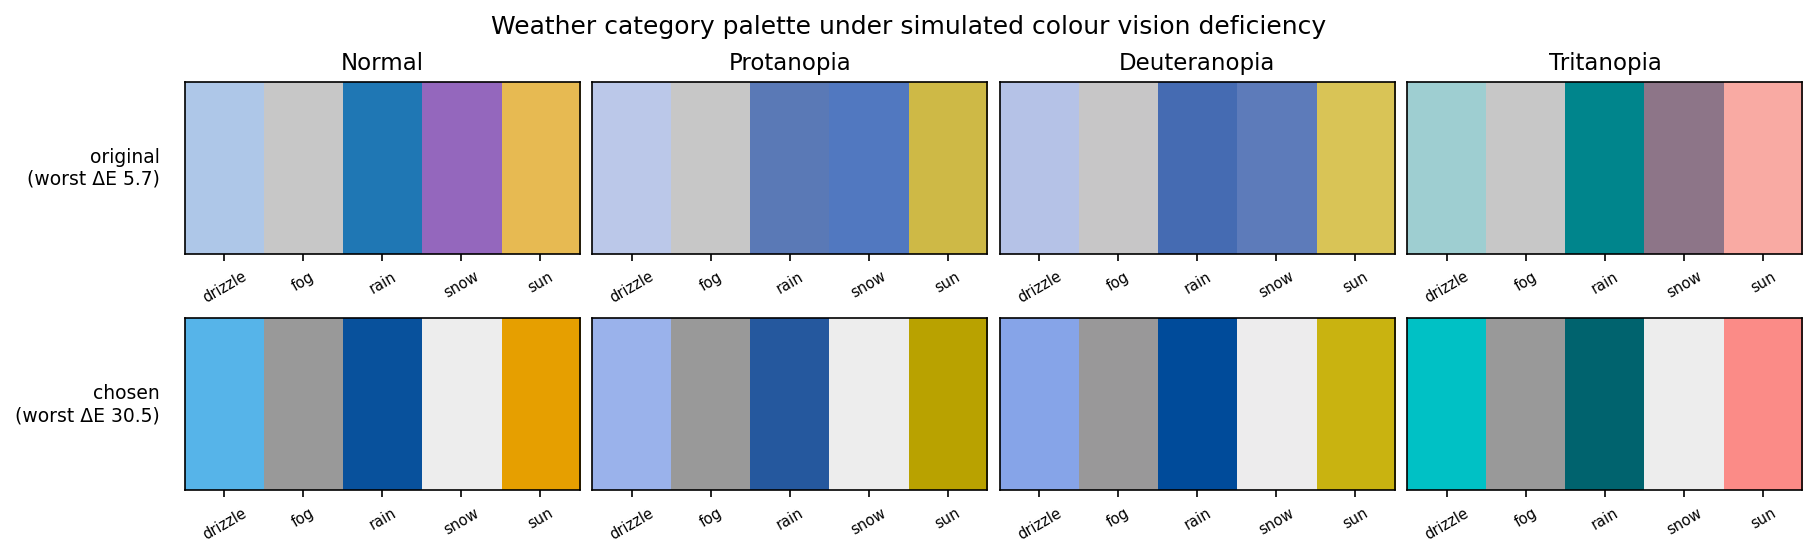

In [5]:
from IPython.display import Image
Image('palette_check.png')

## Export

In [6]:
dashboard.save('solution.html')
print('saved solution.html')

saved solution.html
